<a href="https://colab.research.google.com/github/minxuan0923/AML_Assignment/blob/yy/Set3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import Libaries

In [1]:
import pandas as pd
import numpy as np
from scipy.io import arff
import requests
from io import StringIO

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import PolynomialFeatures

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import tensorflow as tf
from tensorflow.keras import layers, models, losses
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(42)

## Load Dataset

In [2]:
URL = (
    "https://raw.githubusercontent.com/"
    "minxuan0923/AML_Assignment/main/data/"
    "UCI_Phishing_Training_Dataset.arff"
)

response = requests.get(URL, timeout=30)
response.raise_for_status()

data, meta = arff.loadarff(StringIO(response.text))

df = pd.DataFrame(data)

for col in df.select_dtypes([object]):
    df[col] = pd.to_numeric(
        df[col].str.decode('utf-8')
    )

## Dataset Exploration


In [3]:
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nClass distribution:")
print(df['Result'].value_counts())

Dataset shape: (11055, 31)

First 5 rows:


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1



Missing values:
0

Class distribution:
Result
 1    6157
-1    4898
Name: count, dtype: int64


## Seperation Input and Output

In [4]:
x_data = df.drop(columns=['Result'])
y_data = df['Result']

## Spliting

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    x_data,
    y_data,
    random_state=42,
    test_size=0.2,
    stratify=y_data
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (8844, 30)
Testing set: (2211, 30)


## Encoding

In [6]:
encoder = OneHotEncoder(sparse_output=False)

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

print("Before encoding:", X_train.shape)
print("After encoding:", X_train_encoded.shape)

Before encoding: (8844, 30)
After encoding: (8844, 68)


## Convert Output Labels

In [7]:
# Convert phishing to 1 and legitimate to 0

y_train = y_train.replace({-1: 1, 1: 0})
y_test = y_test.replace({-1: 1, 1: 0})

print("Training label distribution:")
print(y_train.value_counts())

print("Testing label distribution:")
print(y_test.value_counts())

Training label distribution:
Result
0    4926
1    3918
Name: count, dtype: int64
Testing label distribution:
Result
0    1231
1     980
Name: count, dtype: int64


## Generate Interaction Features

In [8]:
interaction = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X_train_interaction = interaction.fit_transform(
    X_train_encoded
)

X_test_interaction = interaction.transform(
    X_test_encoded
)

print("Before interaction:",
      X_train_encoded.shape)

print("After interaction:",
      X_train_interaction.shape)

print("Number of new features:",
      X_train_interaction.shape[1]
      - X_train_encoded.shape[1])

Before interaction: (8844, 68)
After interaction: (8844, 2346)
Number of new features: 2278


## Logistic Regression

In [9]:
X_train_lr, X_val_lr, y_train_lr, y_val_lr = train_test_split(
    X_train_interaction,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training shape:", X_train_lr.shape)
print("Validation shape:", X_val_lr.shape)
print("Testing shape:", X_test_interaction.shape)

Training shape: (7075, 2346)
Validation shape: (1769, 2346)
Testing shape: (2211, 2346)


In [10]:
normalizer = layers.Normalization(axis=None)

normalizer.adapt(X_train_lr)

In [11]:
logistic_model = models.Sequential()

logistic_model.add(
    layers.Input(
        shape=(X_train_interaction.shape[1],)
    )
)

logistic_model.add(normalizer)

logistic_model.add(
    layers.Dense(1, activation='sigmoid')
)

logistic_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=losses.binary_crossentropy,
    metrics=['accuracy']
)

logistic_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 2346)           │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,347 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,350 (9.18 KB)

 Trainable params: 2,347 (9.17 KB)

 Non-trainable params: 3 (16.00 B)

In [12]:
history_lr = logistic_model.fit(
    X_train_lr,
    y_train_lr,
    epochs=50,
    batch_size=32,
    validation_data=(X_val_lr, y_val_lr)
)

Epoch 1/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9156 - loss: 0.2038 - val_accuracy: 0.9565 - val_loss: 0.1219
Epoch 2/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9415 - loss: 0.1396 - val_accuracy: 0.9565 - val_loss: 0.1100
Epoch 3/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9476 - loss: 0.1270 - val_accuracy: 0.9553 - val_loss: 0.1034
Epoch 4/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9511 - loss: 0.1192 - val_accuracy: 0.9587 - val_loss: 0.0992
Epoch 5/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9535 - loss: 0.1138 - val_accuracy: 0.9599 - val_loss: 0.0963
Epoch 6/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9543 - loss: 0.1097 - val_accuracy: 0.9599 - val_loss: 0.0941
Epoch 7/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9552 - loss: 0.1066 - val_accuracy: 0.9621 - val_loss: 0.0924
Epoch 8/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9569 - loss: 0.1039 - val_accuracy: 

In [13]:
test_loss, test_accuracy = logistic_model.evaluate(
    X_test_interaction,
    y_test
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9647 - loss: 0.0957
Test Accuracy: 0.9647218585014343
Test Loss: 0.09571891278028488


## Model Prediction

In [14]:
y_prob = logistic_model.predict(
    X_test_interaction
).ravel()

y_pred = (y_prob > 0.5).astype(int)

print("Predicted probabilities:", y_prob[:10])
print("Predicted classes:", y_pred[:10])

70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Predicted probabilities: [1.0000000e+00 9.9151409e-01 3.3126662e-16 1.0000000e+00 9.9998403e-01
 5.1937814e-09 2.4473449e-04 4.4077805e-08 3.0444795e-03 9.9608177e-01]
Predicted classes: [1 1 0 1 1 0 0 0 0 1]


## Performance Evalation

In [15]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

TN, FP, FN, TP = cm.ravel()

fnr = FN / (FN + TP)

print("Experiment 3 Results")
print("-----------------------------")
print(f"Accuracy:            {accuracy:.4f}")
print(f"Precision:           {precision:.4f}")
print(f"Recall:              {recall:.4f}")
print(f"F1-score:            {f1:.4f}")
print(f"ROC-AUC:             {auc:.4f}")
print(f"False Negative Rate: {fnr:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['Legitimate', 'Phishing']
))

Experiment 3 Results
-----------------------------
Accuracy:            0.9647
Precision:           0.9640
Recall:              0.9561
F1-score:            0.9600
ROC-AUC:             0.9946
False Negative Rate: 0.0439

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.97      0.97      0.97      1231
    Phishing       0.96      0.96      0.96       980

    accuracy                           0.96      2211
   macro avg       0.96      0.96      0.96      2211
weighted avg       0.96      0.96      0.96      2211



## Confision Matrix

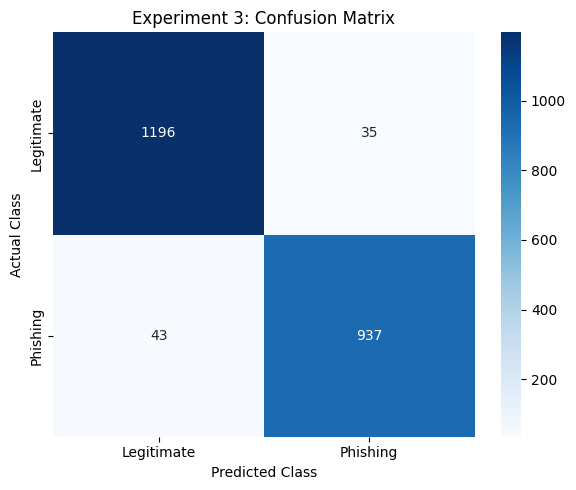

In [16]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Phishing'],
    yticklabels=['Legitimate', 'Phishing']
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Experiment 3: Confusion Matrix')

plt.tight_layout()
plt.savefig('Set3_Confusion_Matrix.png', dpi=300)
plt.show()

## ROC Curve

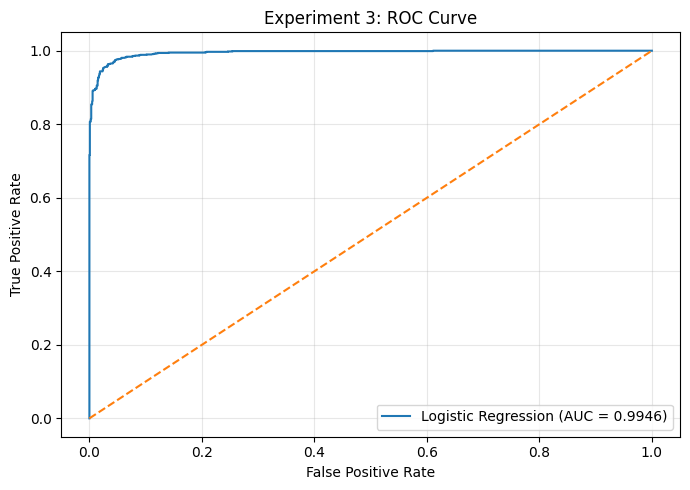

In [17]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {auc:.4f})'
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Experiment 3: ROC Curve')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Set3_ROC_Curve.png', dpi=300)
plt.show()

## Check Overfitting

In [18]:
train_loss, train_accuracy = logistic_model.evaluate(
    X_train_lr,
    y_train_lr,
    verbose=0
)

val_loss, val_accuracy = logistic_model.evaluate(
    X_val_lr,
    y_val_lr,
    verbose=0
)

print(f"Training Accuracy:   {train_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Testing Accuracy:    {test_accuracy:.4f}")

print(f"Training Loss:       {train_loss:.4f}")
print(f"Validation Loss:     {val_loss:.4f}")
print(f"Testing Loss:        {test_loss:.4f}")

print(f"Train-Val Accuracy Gap: "
      f"{train_accuracy - val_accuracy:.4f}")

Training Accuracy:   0.9744
Validation Accuracy: 0.9633
Testing Accuracy:    0.9647
Training Loss:       0.0637
Validation Loss:     0.0855
Testing Loss:        0.0957
Train-Val Accuracy Gap: 0.0112


## Plot Traning and Validation Accurary

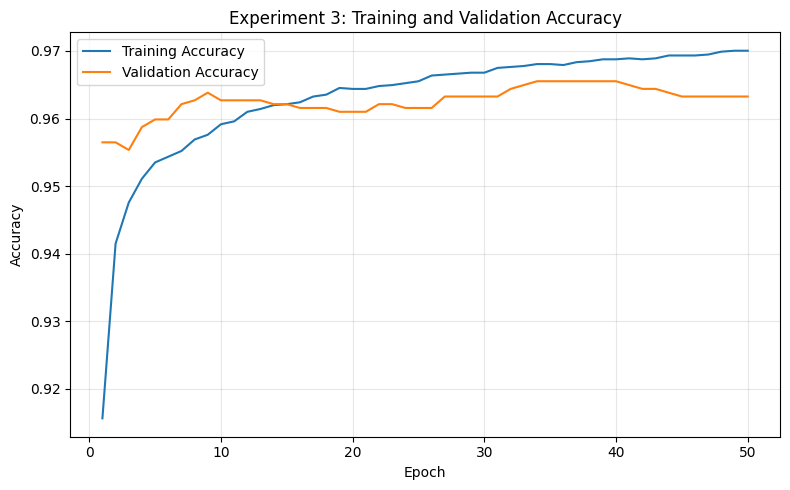

In [19]:
epochs = range(1, len(history_lr.history['accuracy']) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_lr.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    epochs,
    history_lr.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Experiment 3: Training and Validation Accuracy')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Set3_Accuracy_Curve.png', dpi=300)
plt.show()

## Plot Training and Validation Loss

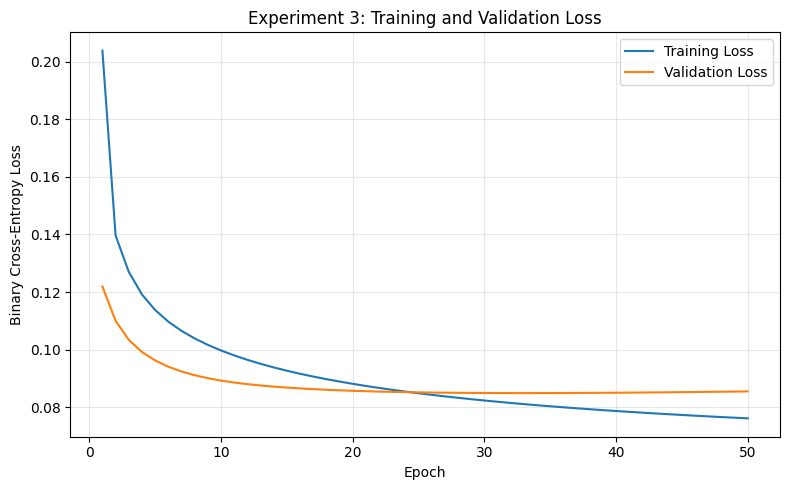

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_lr.history['loss'],
    label='Training Loss'
)

plt.plot(
    epochs,
    history_lr.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.title('Experiment 3: Training and Validation Loss')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Set3_Loss_Curve.png', dpi=300)
plt.show()

In [21]:
results = pd.DataFrame({
    'Experiment': [3],
    'Feature Representation': ['Interaction Features'],
    'Model': ['Logistic Regression'],
    'Accuracy': [accuracy],
    'Precision': [precision],
    'Recall': [recall],
    'F1-score': [f1],
    'ROC-AUC': [auc],
    'False Negative Rate': [fnr],
    'Test Loss': [test_loss],
    'TN': [TN],
    'FP': [FP],
    'FN': [FN],
    'TP': [TP]
})

display(results)

results.to_csv('Set3_Results.csv', index=False)

,Experiment,Feature Representation,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,False Negative Rate,Test Loss,TN,FP,FN,TP
0,3,Interaction Features,Logistic Regression,0.964722,0.963992,0.956122,0.960041,0.994554,0.043878,0.095719,1196,35,43,937
